# 4. Baseline Model Development

This section establishes an initial machine learning baseline for predicting air temperature using geographical and temporal features.

The prediction target is `temperature_celsius`.

The initial model will use spatial and temporal information to establish a reference performance before exploring more advanced models.

A chronological train-test split will be used to reduce temporal data leakage.

Model performance will be evaluated using regression metrics.

### 4.1 Loading the Processed Dataset

The processed dataset containing the engineered spatial features is loaded from the processed data directory.

The dataset structure, data types, and available columns are inspected before preparing the baseline model.

In [1]:
# Standard Libraries
import sys
import time
from pathlib import Path

# Add Project Root to Python Path
sys.path.insert(0, str(Path.cwd().parent))

# Data Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Scikit-learn
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Project Configuration
from config import (
    PROJECT_ROOT,
    PROCESSED_DATA_PATH,
    FIGURES_DIR,
    RESULTS_DIR,
    MODELS_DIR,
    RANDOM_STATE
)

# Load Processed Dataset
df = pd.read_csv(PROCESSED_DATA_PATH)

df["last_updated"] = pd.to_datetime(df["last_updated"])

print("Dataset shape:", df.shape)

print("\nDataset columns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nTarget statistics:")
display(df["temperature_celsius"].describe())

Dataset shape: (170928, 44)

Dataset columns:
['country', 'location_name', 'latitude', 'longitude', 'timezone', 'last_updated_epoch', 'last_updated', 'temperature_celsius', 'temperature_fahrenheit', 'condition_text', 'wind_mph', 'wind_kph', 'wind_degree', 'wind_direction', 'pressure_mb', 'pressure_in', 'precip_mm', 'precip_in', 'humidity', 'cloud', 'feels_like_celsius', 'feels_like_fahrenheit', 'visibility_km', 'visibility_miles', 'uv_index', 'gust_mph', 'gust_kph', 'air_quality_Carbon_Monoxide', 'air_quality_Ozone', 'air_quality_Nitrogen_dioxide', 'air_quality_Sulphur_dioxide', 'air_quality_PM2.5', 'air_quality_PM10', 'air_quality_us-epa-index', 'air_quality_gb-defra-index', 'sunrise', 'sunset', 'moonrise', 'moonset', 'moon_phase', 'moon_illumination', 'abs_latitude', 'is_northern_hemisphere', 'is_eastern_hemisphere']

Data types:
country                                    str
location_name                              str
latitude                               float64
longitude      

count    170928.000000
mean         21.445260
std           9.271741
min         -29.800000
25%          16.200000
50%          23.600000
75%          27.700000
max          79.300000
Name: temperature_celsius, dtype: float64

### 4.2 Target Variable Quality Check

Before training the baseline model, the target variable is examined for potentially unrealistic temperature values.

This step helps identify extreme observations that may affect model training and evaluation.

The original records will be inspected before making any data-cleaning decisions.

In [2]:
print("Temperature values above 50°C:")

extreme_temperatures = df[
    df["temperature_celsius"] > 50
].sort_values(
    "temperature_celsius",
    ascending=False
)

display(
    extreme_temperatures[
        [
            "country",
            "location_name",
            "last_updated",
            "latitude",
            "longitude",
            "temperature_celsius"
        ]
    ].head(20)
)

print("\nNumber of records above 50°C:")
print(len(extreme_temperatures))

print("\nNumber of records below -20°C:")
print((df["temperature_celsius"] < -20).sum())

Temperature values above 50°C:


,country,location_name,last_updated,latitude,longitude,temperature_celsius
137276,Fiji Islands,Suva,2026-04-24 18:30:00,-18.1333,178.4167,79.3



Number of records above 50°C:
1

Number of records below -20°C:
102


### 4.3 Investigating Extreme Temperature Values

The initial target variable inspection identified one unusually high temperature value and several observations below -20°C.

This section examines the unusually low temperature records to distinguish potentially valid cold-weather observations from data quality issues.

No observations will be removed without sufficient justification.

In [3]:
low_temperatures = df[
    df["temperature_celsius"] < -20
].sort_values(
    "temperature_celsius"
)

display(
    low_temperatures[
        [
            "country",
            "location_name",
            "last_updated",
            "latitude",
            "longitude",
            "temperature_celsius"
        ]
    ].head(20)
)

print("Total records below -20°C:", len(low_temperatures))

print("\nCountries represented:")
display(
    low_temperatures["country"].value_counts().head(15)
)

print("\nTemperature statistics below -20°C:")
display(low_temperatures["temperature_celsius"].describe())

,country,location_name,last_updated,latitude,longitude,temperature_celsius
118990,Mongolia,Ulaanbaatar,2026-01-18 15:00:00,47.9167,106.9167,-29.8
119182,Mongolia,Ulaanbaatar,2026-01-20 15:15:00,47.9167,106.9167,-28.9
121617,Belarus,Minsk,2026-02-02 10:00:00,53.9000,27.5667,-26.9
118606,Mongolia,Ulaanbaatar,2026-01-16 15:15:00,47.9167,106.9167,-26.8
118801,Mongolia,Ulaanbaatar,2026-01-17 15:00:00,47.9167,106.9167,-25.9
118507,Belarus,Minsk,2026-01-16 10:15:00,53.9000,27.5667,-25.8
115680,Russia,Chi-Chi-Erh,2026-01-01 14:15:00,51.7000,94.4500,-25.8
119376,Mongolia,Ulaanbaatar,2026-01-21 15:00:00,47.9167,106.9167,-25.7
118774,Kazakhstan,Astana,2026-01-17 12:00:00,51.1811,71.4278,-25.7
159700,Iceland,Abaer,2026-08-17 06:00:00,65.3000,-18.8667,-25.4


Total records below -20°C: 102

Countries represented:


country
Mongolia      42
Kazakhstan    20
Russia        14
Belarus        9
Canada         7
Finland        4
Latvia         3
Iceland        1
Lithuania      1
Ukraine        1
Name: count, dtype: int64


Temperature statistics below -20°C:


count    102.000000
mean     -22.620588
std        1.913078
min      -29.800000
25%      -23.800000
50%      -21.900000
75%      -21.000000
max      -20.100000
Name: temperature_celsius, dtype: float64

### 4.4 Investigating the Extreme High Temperature

One observation with a temperature of 79.3°C was identified in Suva, Fiji.

Before excluding this observation, nearby temperature records from the same location are examined to determine whether the value is an isolated anomaly or part of a broader temperature pattern.

In [4]:
# Inspect temperature records around the extreme observation

extreme_record = df.loc[
    df["temperature_celsius"].idxmax()
]

extreme_date = extreme_record["last_updated"]

suva_records = df[
    (df["country"] == extreme_record["country"]) &
    (df["location_name"] == extreme_record["location_name"]) &
    (
        df["last_updated"].between(
            extreme_date - pd.Timedelta(hours=24),
            extreme_date + pd.Timedelta(hours=24)
        )
    )
].sort_values("last_updated")

display(
    suva_records[
        [
            "last_updated",
            "temperature_celsius",
            "humidity",
            "wind_kph",
            "pressure_mb"
        ]
    ]
)

,last_updated,temperature_celsius,humidity,wind_kph,pressure_mb
137081,2026-04-23 18:30:00,26.4,89,15.5,1013.0
137276,2026-04-24 18:30:00,79.3,7,16.2,1013.0
137471,2026-04-25 18:30:00,25.4,100,8.3,1011.0


In [5]:
print("Number of nearby records:", len(suva_records))

print("\nNearby temperature statistics:")
display(suva_records["temperature_celsius"].describe())

Number of nearby records: 3

Nearby temperature statistics:


count     3.000000
mean     43.700000
std      30.834559
min      25.400000
25%      25.900000
50%      26.400000
75%      52.850000
max      79.300000
Name: temperature_celsius, dtype: float64

#### Key Findings

The investigation identified one anomalous temperature observation in Suva, Fiji.

The recorded temperature reached 79.3°C on April 24, 2026, while the observations on the preceding and following days were 26.4°C and 25.4°C, respectively.

The anomalous observation also showed an unusual humidity value of 7%, compared with 89% and 100% in the surrounding observations.

Based on these inconsistencies, the observation will be excluded from model training.

The 102 observations below -20°C will be retained because they are associated with geographically cold regions and are not sufficient evidence of data errors.

### 4.5 Removing the Confirmed Anomalous Observation

The identified anomalous observation is excluded from the modeling dataset.

All other temperature observations, including valid extreme cold-weather records, are retained.

In [6]:
# Remove the confirmed anomalous observation

df_model = df.drop(
    index=extreme_record.name
).copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_model.shape)

print(
    "\nRemaining records above 50°C:",
    (df_model["temperature_celsius"] > 50).sum()
)

print(
    "Remaining records below -20°C:",
    (df_model["temperature_celsius"] < -20).sum()
)

Original dataset shape: (170928, 44)
Cleaned dataset shape: (170927, 44)

Remaining records above 50°C: 0
Remaining records below -20°C: 102


#### Key Findings

The confirmed anomalous observation (79.3°C) was successfully removed from the modeling dataset.

- Original dataset: 170,928 records.
- Cleaned dataset: 170,927 records.
- Records above 50°C after cleaning: 0.
- Records below -20°C retained: 102.
- No columns were removed.

The original dataset remains unchanged, while the cleaned dataset is stored separately in memory as `df_model`.

### 4.6 Feature Selection & Temporal Feature Engineering

The baseline model will initially use geographical coordinates and temporal features to predict air temperature.

The original latitude and longitude values will represent geographical information.

Temporal features will be extracted from the observation timestamp to capture seasonal and daily temperature patterns.

Features directly derived from the target variable will be excluded to prevent data leakage.

#### 4.6.1 Creating Temporal Features

The observation timestamp is used to extract temporal information.

The following features are created:

- `month`: Month of the year.
- `hour`: Hour of the day.
- `day_of_year`: Day of the year.

Cyclical encoding is applied to represent the periodic nature of months, hours, and days of the year.

This prevents the model from treating the end and beginning of a cycle as unrelated values.

In [7]:
# Create temporal features

df_model["month"] = df_model["last_updated"].dt.month
df_model["hour"] = df_model["last_updated"].dt.hour
df_model["day_of_year"] = df_model["last_updated"].dt.dayofyear

# Cyclical encoding

df_model["month_sin"] = np.sin(
    2 * np.pi * df_model["month"] / 12
)

df_model["month_cos"] = np.cos(
    2 * np.pi * df_model["month"] / 12
)

df_model["hour_sin"] = np.sin(
    2 * np.pi * df_model["hour"] / 24
)

df_model["hour_cos"] = np.cos(
    2 * np.pi * df_model["hour"] / 24
)

df_model["day_sin"] = np.sin(
    2 * np.pi * df_model["day_of_year"] / 365.25
)

df_model["day_cos"] = np.cos(
    2 * np.pi * df_model["day_of_year"] / 365.25
)

print("Updated dataset shape:", df_model.shape)

display(
    df_model[
        [
            "last_updated",
            "month",
            "hour",
            "day_of_year",
            "month_sin",
            "month_cos",
            "hour_sin",
            "hour_cos",
            "day_sin",
            "day_cos"
        ]
    ].head(10)
)

Updated dataset shape: (170927, 53)


C:\Users\mosab\AppData\Local\Temp\ipykernel_20292\3998151774.py:5: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  df_model["day_of_year"] = df_model["last_updated"].dt.dayofyear


,last_updated,month,hour,day_of_year,month_sin,month_cos,hour_sin,hour_cos,day_sin,day_cos
0,2024-05-16 13:15:00,5,13,137,0.5,-0.866025,-2.588190e-01,-9.659258e-01,0.706727,-0.707487
1,2024-05-16 10:45:00,5,10,137,0.5,-0.866025,5.000000e-01,-8.660254e-01,0.706727,-0.707487
2,2024-05-16 09:45:00,5,9,137,0.5,-0.866025,7.071068e-01,-7.071068e-01,0.706727,-0.707487
3,2024-05-16 10:45:00,5,10,137,0.5,-0.866025,5.000000e-01,-8.660254e-01,0.706727,-0.707487
4,2024-05-16 09:45:00,5,9,137,0.5,-0.866025,7.071068e-01,-7.071068e-01,0.706727,-0.707487
5,2024-05-16 04:45:00,5,4,137,0.5,-0.866025,8.660254e-01,5.000000e-01,0.706727,-0.707487
6,2024-05-16 05:45:00,5,5,137,0.5,-0.866025,9.659258e-01,2.588190e-01,0.706727,-0.707487
7,2024-05-16 12:45:00,5,12,137,0.5,-0.866025,1.224647e-16,-1.000000e+00,0.706727,-0.707487
8,2024-05-16 18:45:00,5,18,137,0.5,-0.866025,-1.000000e+00,-1.836970e-16,0.706727,-0.707487
9,2024-05-16 10:45:00,5,10,137,0.5,-0.866025,5.000000e-01,-8.660254e-01,0.706727,-0.707487


#### 4.6.2 Selecting Baseline Features

The initial baseline feature set consists of:

**Geographical Features:**
- `latitude`
- `longitude`

**Temporal Features:**
- `month_sin`
- `month_cos`
- `hour_sin`
- `hour_cos`
- `day_sin`
- `day_cos`

The target variable is `temperature_celsius`.

Weather measurements that may directly reveal or be derived from the target variable are excluded from the initial baseline model.

The engineered hemisphere indicators and absolute latitude are not included in this initial feature set because they are derived from the original coordinates. Their additional predictive contribution can be evaluated in later experiments.

In [8]:
# Define baseline features and target

feature_columns = [
    "latitude",
    "longitude",
    "month_sin",
    "month_cos",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos"
]

target_column = "temperature_celsius"

X = df_model[feature_columns].copy()
y = df_model[target_column].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nSelected features:")
print(feature_columns)

print("\nMissing values in X:")
print(X.isnull().sum())

print("\nMissing values in y:")
print(y.isnull().sum())

Feature matrix shape: (170927, 8)
Target shape: (170927,)

Selected features:
['latitude', 'longitude', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos']

Missing values in X:
latitude     0
longitude    0
month_sin    0
month_cos    0
hour_sin     0
hour_cos     0
day_sin      0
day_cos      0
dtype: int64

Missing values in y:
0


#### Key Findings

Eight features were selected for the initial baseline model, combining geographical coordinates with cyclical temporal features.

- Feature matrix: 170,927 rows × 8 features.
- Target vector: 170,927 observations.
- No missing values were found in the selected features or target.
- Cyclical encoding was successfully applied to represent monthly, daily, and hourly patterns.

The selected features are ready for the initial chronological data split.

### 4.7 Chronological Train-Test Split

The dataset is split chronologically to ensure that the model is trained on earlier observations and evaluated on later observations.

The first 80% of the chronological observations are used for training, while the remaining 20% are reserved for testing.

This approach better reflects the use of historical weather data to predict future observations and avoids random row-level splitting.

In [9]:
# Sort observations chronologically

df_model = df_model.sort_values(
    "last_updated"
).reset_index(drop=True)

# Define chronological split point

split_index = int(len(df_model) * 0.80)

train_df = df_model.iloc[:split_index].copy()
test_df = df_model.iloc[split_index:].copy()

# Separate features and target

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Display split information

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining period:")
print(train_df["last_updated"].min(), "to", train_df["last_updated"].max())

print("\nTesting period:")
print(test_df["last_updated"].min(), "to", test_df["last_updated"].max())

print("\nSplit ratio:")
print(f"Training: {len(train_df) / len(df_model):.2%}")
print(f"Testing: {len(test_df) / len(df_model):.2%}")

Training shape: (136741, 8)
Testing shape: (34186, 8)

Training period:
2024-05-16 01:45:00 to 2026-04-21 08:45:00

Testing period:
2026-04-21 08:45:00 to 2026-10-13 18:45:00

Split ratio:
Training: 80.00%
Testing: 20.00%


#### Chronological Split Refinement

The initial chronological split revealed an overlapping timestamp between the training and testing sets.

To prevent observations with the same timestamp from appearing in both sets, the split boundary is adjusted using a unique timestamp.

All observations before the boundary are assigned to training, while observations at or after the boundary are assigned to testing.

In [10]:
# Sort observations using absolute Unix timestamps

df_model = df_model.sort_values(
    "last_updated_epoch"
).reset_index(drop=True)

# Use unique timestamps to prevent timestamp overlap

unique_timestamps = np.sort(
    df_model["last_updated_epoch"].unique()
)

split_index = int(len(unique_timestamps) * 0.80)

split_timestamp = unique_timestamps[split_index]

# Create chronological train-test sets

train_df = df_model[
    df_model["last_updated_epoch"] < split_timestamp
].copy()

test_df = df_model[
    df_model["last_updated_epoch"] >= split_timestamp
].copy()

# Separate features and target

X_train = train_df[feature_columns]
y_train = train_df[target_column]

X_test = test_df[feature_columns]
y_test = test_df[target_column]

# Display results

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining period (local timestamps):")
print(train_df["last_updated"].min(), "to",
      train_df["last_updated"].max())

print("\nTesting period (local timestamps):")
print(test_df["last_updated"].min(), "to",
      test_df["last_updated"].max())

print("\nSplit ratio:")
print(f"Training: {len(train_df) / len(df_model):.2%}")
print(f"Testing: {len(test_df) / len(df_model):.2%}")

# Verify timestamp separation

print("\nMaximum training Unix timestamp:",
      train_df["last_updated_epoch"].max())

print("Minimum testing Unix timestamp:",
      test_df["last_updated_epoch"].min())

print("\nTimestamp overlap:",
      len(
          set(train_df["last_updated_epoch"])
          & set(test_df["last_updated_epoch"])
      ))

Training shape: (135268, 8)
Testing shape: (35659, 8)

Training period (local timestamps):
2024-05-16 01:45:00 to 2026-04-13 20:00:00

Testing period (local timestamps):
2026-04-14 00:00:00 to 2026-10-13 18:45:00

Split ratio:
Training: 79.14%
Testing: 20.86%

Maximum training Unix timestamp: 1776063600
Minimum testing Unix timestamp: 1776150000

Timestamp overlap: 0


#### 4.8.1 Training the Baseline Models

Two regression models are trained using the selected geographical and temporal features.

1. **Dummy Regressor:** Uses the mean target value from the training set as a simple prediction baseline.
2. **Random Forest Regressor:** Learns nonlinear relationships between geographical coordinates, temporal patterns, and temperature.

Both models are trained using the same training data and evaluated later on the same unseen test set.

In [11]:
# Initialize models

dummy_model = DummyRegressor(strategy="mean")

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train Dummy Regressor

start_time = time.time()

dummy_model.fit(X_train, y_train)

dummy_training_time = time.time() - start_time

print(f"Dummy training time: {dummy_training_time:.2f} seconds")

# Train Random Forest

start_time = time.time()

rf_model.fit(X_train, y_train)

rf_training_time = time.time() - start_time

print(f"Random Forest training time: {rf_training_time:.2f} seconds")

print("\nBoth models trained successfully.")

Dummy training time: 0.04 seconds
Random Forest training time: 2.91 seconds

Both models trained successfully.


### 4.9 Model Evaluation

The trained models are evaluated using the unseen test dataset.

Predictions are generated for both the Dummy Regressor and Random Forest models to compare their predictive performance.

#### 4.9.1 Generating Predictions

The trained models generate temperature predictions using the test feature matrix.

The predicted values are stored for subsequent evaluation using regression metrics.

In [12]:
# Generate predictions

dummy_predictions = dummy_model.predict(X_test)

rf_predictions = rf_model.predict(X_test)

print("Dummy predictions shape:", dummy_predictions.shape)
print("Random Forest predictions shape:", rf_predictions.shape)

print("\nActual temperatures:")
print(y_test.head(10).values)

print("\nRandom Forest predictions:")
print(rf_predictions[:10])

Dummy predictions shape: (35659,)
Random Forest predictions shape: (35659,)

Actual temperatures:
[24.3 20.3 26.4 22.1  7.8 25.1 24.8 26.4 30.  25.2]

Random Forest predictions:
[28.05895714 20.59542262 27.4640619  22.85009524  7.81200476 25.35283294
 25.04802222 25.06005238 31.23069127 26.0694829 ]


#### 4.9.2 Regression Performance Metrics

The predictive performance of both models is evaluated using three regression metrics:

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted temperatures.
- **RMSE (Root Mean Squared Error):** Penalizes larger prediction errors more strongly.
- **R² Score:** Measures how much of the target variance is explained by the model.

The same test dataset is used to evaluate both models for a fair comparison.

In [13]:
# Evaluate Dummy Regressor

dummy_mae = mean_absolute_error(y_test, dummy_predictions)
dummy_rmse = np.sqrt(mean_squared_error(y_test, dummy_predictions))
dummy_r2 = r2_score(y_test, dummy_predictions)

# Evaluate Random Forest

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# Compare model performance

evaluation_results = pd.DataFrame({
    "Model": ["Dummy Regressor", "Random Forest"],
    "MAE": [dummy_mae, rf_mae],
    "RMSE": [dummy_rmse, rf_rmse],
    "R2 Score": [dummy_r2, rf_r2]
})

display(evaluation_results.round(4))

,Model,MAE,RMSE,R2 Score
0,Dummy Regressor,6.0833,7.4380,-0.0112
1,Random Forest,3.0329,4.1914,0.6789


#### Key Findings

The Random Forest Regressor significantly outperformed the Dummy Regressor on the test dataset.

- Random Forest MAE: 3.0329°C.
- Random Forest RMSE: 4.1914°C.
- Random Forest R²: 0.6789.
- Dummy Regressor R²: -0.0112.

The results indicate that geographical and temporal features provide useful information for temperature prediction.

However, further error analysis and spatial validation are required to assess the model's generalization capability.

#### 4.9.3 Prediction Error Analysis

This section examines the prediction errors of the Random Forest model using two visualizations:

- **Actual vs. Predicted:** Compares predicted temperatures against actual temperatures.
- **Residual Distribution:** Examines the distribution of prediction errors.

These visualizations help identify systematic prediction errors and assess how closely the model predictions follow the actual observations.

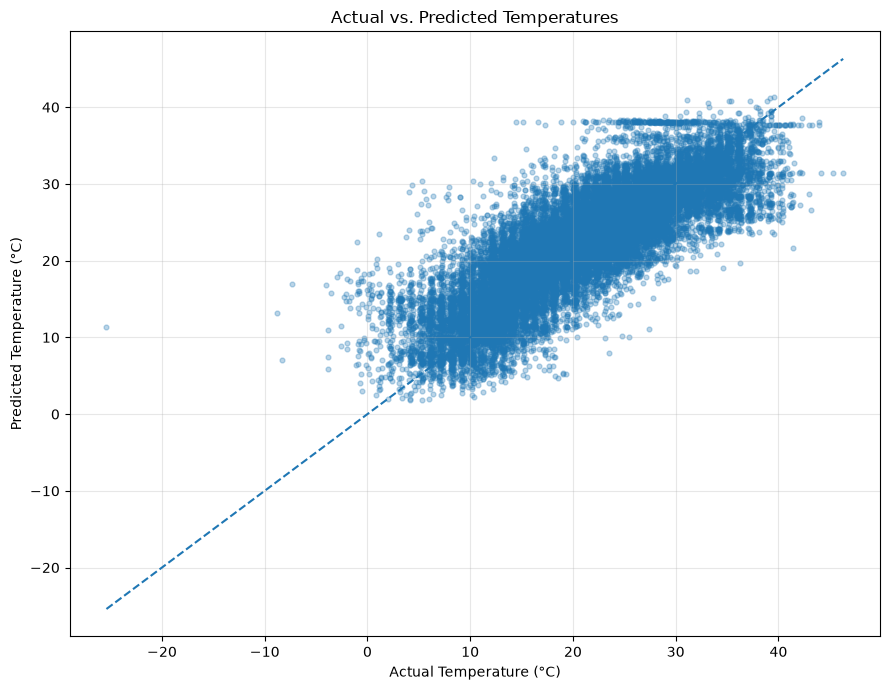

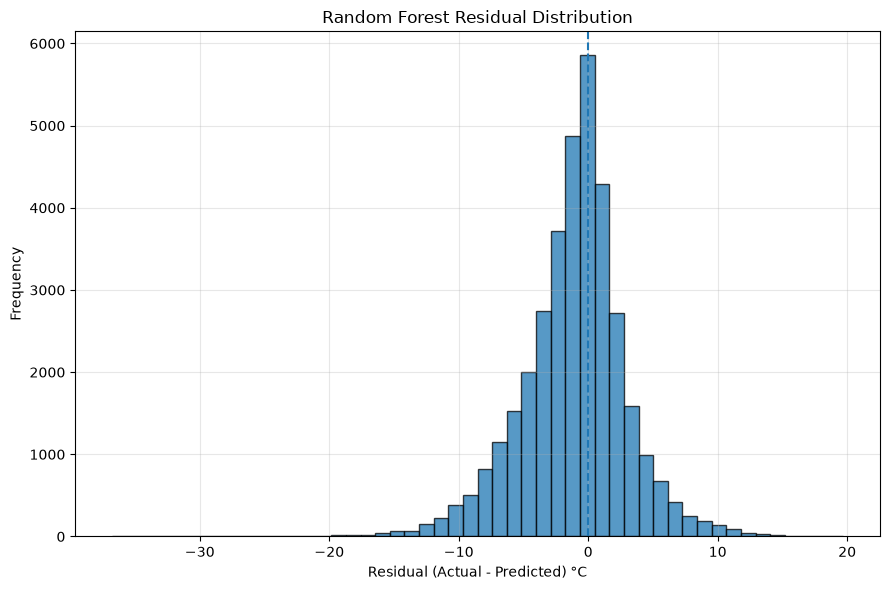

Mean residual: -1.1207978242768133
Residual standard deviation: 4.038794876971407


In [14]:
# Calculate residuals

residuals = y_test.values - rf_predictions

# Create output directory

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Actual vs Predicted

plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.3,
    s=12
)

min_value = min(y_test.min(), rf_predictions.min())
max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs. Predicted Temperatures")
plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Residual Distribution

plt.figure(figsize=(9, 6))

plt.hist(
    residuals,
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(0, linestyle="--")

plt.title("Random Forest Residual Distribution")
plt.xlabel("Residual (Actual - Predicted) °C")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "residual_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Mean residual:", np.mean(residuals))
print("Residual standard deviation:", np.std(residuals))